# 06 Weeks of warning before a peak

**Data:** chosen in `common.py` (`USE_FAKE_DATA`). Chart titles say whether it is real or fake.

The business question from the proposal: **how many weeks before a style reaches its peak does the model first raise an alert?** A buyer needs the warning before the factory lead time runs out (6 weeks in the app's order window), so more warning is better.

**Peak.** Search interest is smoothed with the same 4-week average used for every target. A week is a peak of a style when:

1. its 4-week average is the highest within 8 weeks before and after it, and
2. it is more than 20% above the lowest 4-week average in the 12 weeks before it (the rising threshold of 1.2), and
3. that lowest point is at least 5, the same minimum level LightGBM uses.

The lowest point before the peak is called the **start of the rise**.

**Warning.** For each peak, take the earliest alert the model raised for that style between the start of the rise and the week before the peak. Weeks of warning = peak week minus the week of that alert. A peak with no alert in that window counts as **missed**.

These rules were fixed before looking at any results, using the settings the project already uses (the 1.2 threshold, the minimum level of 5, the 4-week averages).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from common import load_predictions, said_rising, WEEKLY_FILE, RISING_THRESHOLD, DATA_LABEL, FLAGGED_MODEL

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

SIDE = 8          # a peak is the highest point within 8 weeks either side
LOOKBACK = 12     # the start of the rise is the lowest point in the 12 weeks before the peak
MIN_LEVEL = 5     # same minimum level as LightGBM
LEAD_WEEKS = 6    # factory lead time used by the app's order window
MODELS = ["lightgbm", FLAGGED_MODEL, "last_value", "ets", "ridge", "seasonal_naive"]

df = load_predictions()
df["alert"] = said_rising(df)
first_forecast = df["origin"].min()

weekly = pd.read_csv(WEEKLY_FILE, index_col=0, parse_dates=True).sort_index()
avg4 = weekly.rolling(4).mean()
# Peaks need 4 weeks of forecasts before them and 8 weeks of data after them.
earliest_peak = first_forecast + pd.Timedelta(weeks=4)
latest_peak = avg4.index[-1 - SIDE]

C:\Users\tisab\AppData\Local\Temp\ipykernel_11352\3012777260.py:25: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  earliest_peak = first_forecast + pd.Timedelta(weeks=4)


## 1. Find the peaks

Number of peaks in the test period, per month. The spring 2026 surge shows up as many peaks at once in April and May 2026.

In [2]:
rows = []
for style in avg4.columns:
    s = avg4[style].to_numpy()
    for i, week in enumerate(avg4.index):
        if week < earliest_peak or week > latest_peak or i < LOOKBACK or np.isnan(s[i]):
            continue
        if s[i] < np.nanmax(s[i - SIDE:i + SIDE + 1]):
            continue  # not the highest point around it
        before = s[i - LOOKBACK:i]
        start = int(np.nanargmin(before))
        if before[start] < MIN_LEVEL or s[i] <= RISING_THRESHOLD * before[start]:
            continue  # rise too small, or from too low a level
        rows.append({"item": style, "peak": week,
                     "rise_start": max(avg4.index[i - LOOKBACK + start], first_forecast),
                     "rise": s[i] / before[start]})
peaks = pd.DataFrame(rows)
print(f"{len(peaks)} peaks in {peaks['item'].nunique()} styles, {peaks['peak'].min():%d %b %Y} to {peaks['peak'].max():%d %b %Y}")
peaks.groupby(peaks["peak"].dt.to_period("M")).size().rename("peaks").to_frame().T

360 peaks in 134 styles, 23 Feb 2025 to 12 Jul 2026


peak,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07
peaks,1,8,18,12,9,9,53,31,11,26,26,2,26,5,52,67,2,2


## 2. Weeks of warning per model

- **Peaks warned (%)**: share of peaks with at least one alert during the rise.
- **Median weeks of warning**: for the warned peaks only.
- **Warned 6+ weeks ahead (%)**: share of all peaks warned early enough for the 6-week factory lead time.

Alerts come from the 4-week and the 8-week forecasts separately. `lightgbm_flagged` holds back alerts in out-of-range weeks.

In [3]:
def warnings_for(model, horizon):
    """Weeks of warning for every peak (NaN = missed)."""
    alerts = df[(df["model"] == model) & (df["horizon"] == horizon) & df["alert"]][["item", "origin"]]
    during = peaks.merge(alerts, on="item")
    during = during[(during["origin"] >= during["rise_start"]) & (during["origin"] < during["peak"])]
    first_alert = during.groupby(["item", "peak"])["origin"].min().rename("first_alert")
    out = peaks.merge(first_alert, on=["item", "peak"], how="left")
    out["weeks"] = (out["peak"] - out["first_alert"]).dt.days / 7
    return out


def summary(w):
    return pd.Series({"peaks warned (%)": round(100 * w["weeks"].notna().mean(), 1),
                      "median weeks of warning": w["weeks"].median(),
                      f"warned {LEAD_WEEKS}+ weeks ahead (%)": round(100 * (w["weeks"] >= LEAD_WEEKS).mean(), 1)})


results = {(h, m): warnings_for(m, h) for h in (4, 8) for m in MODELS}
pd.DataFrame({key: summary(w) for key, w in results.items()}).T.rename_axis(["horizon", "model"])

peaks warned (%)  median weeks of warning  \
horizon model                                                         
4       lightgbm                      54.2                      7.0   
        lightgbm_flagged              41.7                      7.0   
        last_value                    59.2                      7.0   
        ets                           53.9                      7.0   
        ridge                         48.9                      7.0   
        seasonal_naive                26.9                      9.0   
8       lightgbm                      68.6                      9.0   
        lightgbm_flagged              66.7                      8.0   
        last_value                    59.2                      7.0   
        ets                           55.8                      7.0   
        ridge                         59.7                      8.0   
        seasonal_naive                32.8                     10.0   

                          warned 6+ weeks ahead (%)  
horizon model                                        
4       lightgbm                               38.3  
        lightgbm_flagged                       27.8  
        last_value                             37.2  
        ets                                    38.6  
        ridge                                  33.1  
        seasonal_naive                         24.4  
8       lightgbm                               57.5  
        lightgbm_flagged                       51.9  
        last_value                             37.2  
        ets                                    40.0  
        ridge                                  44.2  
        seasonal_naive                         32.2

## 3. 2025 versus 2026

Most 2026 peaks belong to the market-wide surge, when nearly every style rose at once, so the two years are shown separately.

In [4]:
rows = {}
for (h, m), w in results.items():
    if m in ["lightgbm", FLAGGED_MODEL, "last_value"]:
        for year, g in w.groupby(w["peak"].dt.year):
            rows[(year, h, m)] = summary(g)
table = pd.DataFrame(rows).T.rename_axis(["year", "horizon", "model"]).sort_index()
print({year: int((peaks["peak"].dt.year == year).sum()) for year in (2025, 2026)}, "peaks")
table

{2025: 204, 2026: 156} peaks


peaks warned (%)  median weeks of warning  \
year horizon model                                                         
2025 4       last_value                    31.4                      5.0   
             lightgbm                      35.8                      9.0   
             lightgbm_flagged              35.8                      9.0   
     8       last_value                    31.4                      5.0   
             lightgbm                      55.4                     11.0   
             lightgbm_flagged              55.4                     11.0   
2026 4       last_value                    95.5                      7.0   
             lightgbm                      78.2                      7.0   
             lightgbm_flagged              49.4                      6.0   
     8       last_value                    95.5                      7.0   
             lightgbm                      85.9                      8.0   
             lightgbm_flagged              81.4                      7.0   

                               warned 6+ weeks ahead (%)  
year horizon model                                        
2025 4       last_value                             10.8  
             lightgbm                               27.5  
             lightgbm_flagged                       27.5  
     8       last_value                             10.8  
             lightgbm                               51.0  
             lightgbm_flagged                       51.0  
2026 4       last_value                             71.8  
             lightgbm                               52.6  
             lightgbm_flagged                       28.2  
     8       last_value                             71.8  
             lightgbm                               66.0  
             lightgbm_flagged                       53.2

## 4. How early?

Share of all peaks warned at least *k* weeks ahead. The dashed line is the 6-week factory lead time.

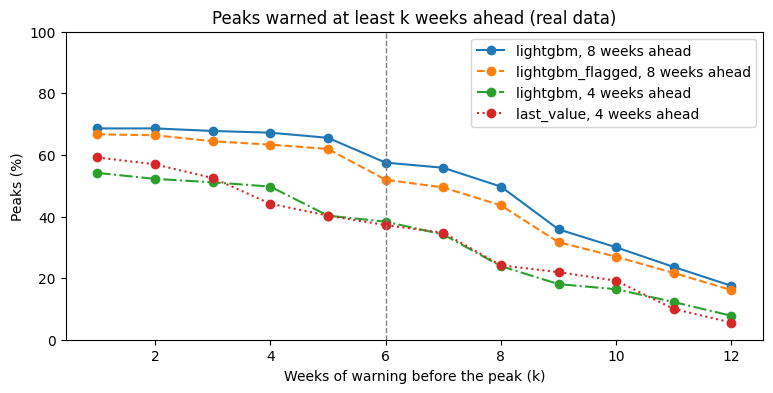

In [5]:
ks = range(1, LOOKBACK + 1)
fig, ax = plt.subplots(figsize=(9, 4))
for (h, m), style in [((8, "lightgbm"), "-"), ((8, FLAGGED_MODEL), "--"), ((4, "lightgbm"), "-."), ((4, "last_value"), ":")]:
    w = results[(h, m)]["weeks"]
    ax.plot(list(ks), [100 * (w >= k).mean() for k in ks], style, marker="o", label=f"{m}, {h} weeks ahead")
ax.axvline(LEAD_WEEKS, color="grey", linestyle="--", linewidth=1)
ax.set_title(f"Peaks warned at least k weeks ahead ({DATA_LABEL})")
ax.set_xlabel("Weeks of warning before the peak (k)")
ax.set_ylabel("Peaks (%)")
ax.set_ylim(0, 100)
ax.legend()
fig.savefig(FIGURES / "06_weeks_of_warning.png", dpi=200, bbox_inches="tight")
plt.show()

## What this shows

Real data, 137 styles, threshold 1.2, test period January 2025 to September 2026: 360 peaks in 134 styles (204 in 2025, 156 in 2026).

1. **2025, a normal year, is the fair test.** Following LightGBM's 8-week alerts, a buyer was warned about
   55.4% of peaks, with a median of 11 weeks of warning, and 51.0% of peaks were warned early enough for a
   6-week factory lead time. Following last value gave 31.4%, a median of 5 weeks, and only 10.8% in time.
   With the 4-week alerts, LightGBM warned 35.8% of peaks (27.5% in time). No forecasts in 2025 were
   flagged, so the out-of-range flag changes nothing there.
2. **Over the whole test at 8 weeks ahead**, LightGBM warned 68.6% of peaks and 57.5% at least 6 weeks
   ahead, the most of any model (Ridge 44.2%, ETS 40.0%, last value 37.2%).
3. **This measure rewards alerting often**, so it must be read together with alert precision (notebook 01).
   In the 2026 surge nearly every style rose at once, and last value, which follows recent movement,
   warned 95.5% of 2026 peaks. That is why last value warns slightly more peaks than LightGBM over the
   full test at 4 weeks (59.2% vs. 54.2%).
4. **The flag costs warnings during the surge.** At 4 weeks ahead, the share of 2026 peaks warned falls
   from 78.2% to 49.4%, because the flag also holds back alerts while the rises were real. At 8 weeks
   ahead the cost is small (85.9% to 81.4%).
5. **Limits:** the earliest alert during a rise counts as the warning even if that 4-week forecast was
   made early in a long rise; the peaks of April and May 2026 are mostly market-wide; the rules for a
   peak (8 weeks either side, 12-week lookback, more than 20% rise) are one reasonable choice, fixed in advance.
